# 11 Model Comparison

**Question.** Does a model that looks at the image and caption *together* beat two separate models? Every model is compared on the same rows and metrics, using the predictions each notebook saved. Nothing is retrained here.

| Model | Notebook | Looks at |
|---|---|---|
| Text only | `06` | caption only |
| Image only | `07` | image only |
| **Baseline Model (Text + Image combined)** | this notebook | both, separately: 06 and 07 combined |
| Simple multimodal model | `09` | both together, one model |
| Stacking | `10` | both together, several models stacked |

- **Baseline Model (Text + Image combined):** two separate models, one sees only the image and one only the caption. Their scores are combined, so it cannot check whether a caption matches its photo.
- **Simple multimodal model:** one model on the image and caption embeddings joined together, so it can check whether they match.
- **Fair comparison:** every model uses CLIP (06 the caption embedding, 07 the image embeddings), so a gain over the baseline comes from combining image and caption, not from having CLIP.

**Rules**
- Each score is checked against the target it predicts.
- Two thresholds per model, both chosen on validation: best F1, and 1% false alarms.
- Test is used once, at the end (`RUN_TEST`).

### Combining Image and Caption Scores

For every model, we combine the two predictions with a simple rule: an image–caption pair counts as genuine only if both its photo and its caption appear genuine. The chance that the pair is fake is therefore

$$P(\text{fake}) = 1 - (1 - p_{\text{image}})(1 - p_{\text{text}})$$

where $p_{\text{image}}$ and $p_{\text{text}}$ are the predicted chances that the photo and the caption were edited.

For the baseline model, $p_{\text{image}}$ comes from the image-only model and $p_{\text{text}}$ from the text-only model. Each multimodal model instead produces both $p_{\text{image}}$ and $p_{\text{text}}$ itself, after seeing the photo and caption together, so its caption score can reflect whether the caption fits the photo.

## 0. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_ROOT = Path("..").resolve()
sys.path.insert(0, str(PROJECT_ROOT))

from src.evaluation import binary_metrics, best_f1_threshold, combine_fake_score, detection_rate_by_type, prevalence_table

PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PREDICTIONS_DIR = PROJECT_ROOT / "results" / "predictions"

TARGETS = ["is_fake", "image_fake", "text_fake"]
TARGET_FPR = 0.01

# Leave False while developing. Set True once, at the end, to report final test results.
RUN_TEST = False

sns.set_theme(style="whitegrid")

## 1. Load Predictions

Each modelling notebook saves `<prefix>_<split>.parquet` with `row_id` and its probability columns. A model whose file is missing is skipped with a message, so this notebook runs with whatever has been saved so far.

In [2]:
LABELS = ["row_id", "id", "fake_cls", "is_fake", "image_fake", "text_fake"]

# Saved predictions of each model: file prefix and the probability columns it provides
SOURCES = {
    "Text only (06)": ("text_model", ["p_text_fake"]),
    "Image only (07)": ("image_model", ["p_image_fake"]),
    "Simple multimodal model (09)": ("early_fusion", ["p_image_fake", "p_text_fake"]),
    "Stacking (10)": ("multimodal_stacking", ["p_image_fake", "p_text_fake"]),
}
BASELINE = "Baseline Model (Text + Image combined)"  # 07 (image only) and 06 (caption only), scores combined


def load_scores(split):
    """Labels of a split and every available model's scores on it, as {model: {target: scores}}."""
    labels = pd.read_parquet(PROCESSED_DIR / f"{split}.parquet", columns=LABELS)
    loaded = {}
    for model, (prefix, cols) in SOURCES.items():
        path = PREDICTIONS_DIR / f"{prefix}_{split}.parquet"
        if not path.exists():
            print(f"{model}: {path.relative_to(PROJECT_ROOT)} not found, skipped")
            continue
        pred = labels[["row_id"]].merge(pd.read_parquet(path, columns=["row_id"] + cols),
                                        on="row_id", how="left", validate="one_to_one")
        assert pred[cols].notna().all().all(), f"{model}: no prediction for some {split} rows"
        loaded[model] = {c.removeprefix("p_"): pred[c].to_numpy() for c in cols}

    scores = {}
    for model in ["Text only (06)", "Image only (07)", BASELINE, "Simple multimodal model (09)", "Stacking (10)"]:
        if model == BASELINE:
            if "Text only (06)" in loaded and "Image only (07)" in loaded:
                scores[model] = {"image_fake": loaded["Image only (07)"]["image_fake"],
                                 "text_fake": loaded["Text only (06)"]["text_fake"]}
        elif model in loaded:
            scores[model] = loaded[model]
    # Pair-level score: fake if either the image or the caption is, the same rule for every model
    for s in scores.values():
        if {"image_fake", "text_fake"} <= s.keys():
            s["is_fake"] = combine_fake_score(s["image_fake"], s["text_fake"])
    # The baseline's image and caption scores are 07's and 06's own, already reported under those models
    if BASELINE in scores:
        scores[BASELINE] = {"is_fake": scores[BASELINE]["is_fake"]}
    return labels, scores


val, val_scores = load_scores("validation")
pd.DataFrame({m: {t: t in s for t in TARGETS} for m, s in val_scores.items()}).T

,is_fake,image_fake,text_fake
Text only (06),False,False,True
Image only (07),False,True,False
Baseline Model (Text + Image combined),True,False,False
Simple multimodal model (09),True,True,True
Stacking (10),True,True,True


## 2. Thresholds (validation)

For each model and target: the best-F1 threshold, and the threshold at which 1% of that target's negatives are flagged.

In [3]:
def fpr_threshold(y, score, rate=TARGET_FPR):
    return float(np.quantile(score[np.asarray(y) == 0], 1 - rate))


thresholds = {}
for model, s in val_scores.items():
    for target, score in s.items():
        thresholds[model, target, "F1"] = best_f1_threshold(val[target], score)
        thresholds[model, target, "FPR1"] = fpr_threshold(val[target], score)

pd.Series(thresholds).unstack().round(3)

F1   FPR1
Baseline Model (Text + Image combined) is_fake     0.422  0.952
Image only (07)                        image_fake  0.399  0.918
Simple multimodal model (09)           image_fake  0.345  0.917
                                       is_fake     0.390  0.953
                                       text_fake   0.440  0.872
Stacking (10)                          image_fake  0.391  0.914
                                       is_fake     0.404  0.945
                                       text_fake   0.417  0.785
Text only (06)                         text_fake   0.198  0.772

## 3. Results by Target

Threshold-free metrics (AUC, PR-AUC, EER), metrics at the F1 threshold, and recall when false alarms are capped at 1%.

In [4]:
METRICS = ["AUC", "PR-AUC", "EER", "Precision", "Recall", "F1"]


def results_table(labels, scores):
    rows = []
    for target in TARGETS:
        y = labels[target].to_numpy()
        for model, s in scores.items():
            if target not in s:
                continue
            m = binary_metrics(y, s[target], thresholds[model, target, "F1"])
            strict = s[target] >= thresholds[model, target, "FPR1"]
            rows.append({"target": target, "model": model, **{k: m[k] for k in METRICS},
                         "FPR at 1% threshold": strict[y == 0].mean(), "Recall at 1% FPR": strict[y == 1].mean()})
    return pd.DataFrame(rows).set_index(["target", "model"])


results_val = results_table(val, val_scores)
results_val.round(3)

AUC  PR-AUC    EER  \
target     model                                                          
is_fake    Baseline Model (Text + Image combined)  0.777   0.875  0.299   
           Simple multimodal model (09)            0.817   0.906  0.273   
           Stacking (10)                           0.872   0.935  0.221   
image_fake Image only (07)                         0.815   0.845  0.272   
           Simple multimodal model (09)            0.797   0.832  0.291   
           Stacking (10)                           0.872   0.895  0.223   
text_fake  Text only (06)                          0.762   0.553  0.314   
           Simple multimodal model (09)            0.894   0.820  0.196   
           Stacking (10)                           0.910   0.840  0.176   

                                                   Precision  Recall     F1  \
target     model                                                              
is_fake    Baseline Model (Text + Image combined)      0.733   0.919  0.815   
           Simple multimodal model (09)                0.735   0.938  0.824   
           Stacking (10)                               0.790   0.919  0.850   
image_fake Image only (07)                             0.673   0.886  0.765   
           Simple multimodal model (09)                0.652   0.906  0.758   
           Stacking (10)                               0.735   0.886  0.803   
text_fake  Text only (06)                              0.429   0.752  0.546   
           Simple multimodal model (09)                0.757   0.671  0.712   
           Stacking (10)                               0.773   0.700  0.735   

                                                   FPR at 1% threshold  \
target     model                                                         
is_fake    Baseline Model (Text + Image combined)                 0.01   
           Simple multimodal model (09)                           0.01   
           Stacking (10)                                          0.01   
image_fake Image only (07)                                        0.01   
           Simple multimodal model (09)                           0.01   
           Stacking (10)                                          0.01   
text_fake  Text only (06)                                         0.01   
           Simple multimodal model (09)                           0.01   
           Stacking (10)                                          0.01   

                                                   Recall at 1% FPR  
target     model                                                     
is_fake    Baseline Model (Text + Image combined)             0.186  
           Simple multimodal model (09)                       0.345  
           Stacking (10)                                      0.409  
image_fake Image only (07)                                    0.231  
           Simple multimodal model (09)                       0.243  
           Stacking (10)                                      0.355  
text_fake  Text only (06)                                     0.109  
           Simple multimodal model (09)                       0.469  
           Stacking (10)                                      0.489

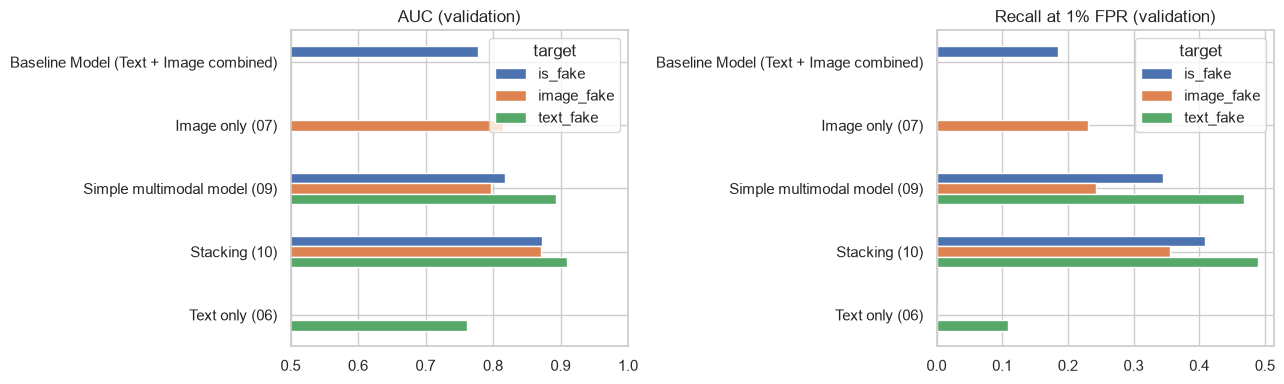

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ["AUC", "Recall at 1% FPR"]):
    results_val[metric].unstack("target")[TARGETS].plot.barh(ax=ax)
    ax.set_title(f"{metric} (validation)")
    ax.set_ylabel("")
    ax.invert_yaxis()
axes[0].set_xlim(0.5, 1.0)
plt.tight_layout()
plt.show()

## 4. What Each Model Catches

Share of each manipulation class flagged by the pair-level `is_fake` score at its 1% false-alarm threshold. For `orig` this is the false-positive rate (1% by construction).

In [6]:
by_type = pd.DataFrame({
    model: detection_rate_by_type(val, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
    for model, s in val_scores.items() if "is_fake" in s
})
by_type.loc[by_type.mean(axis=1).sort_values().index].round(3)

,Baseline Model (Text + Image combined),Simple multimodal model (09),Stacking (10)
fake_cls,,,
orig,0.010,0.010,0.010
text_attribute,0.178,0.063,0.047
face_swap,0.181,0.189,0.322
face_attribute,0.206,0.245,0.312
face_swap&text_attribute,0.371,0.293,0.424
face_attribute&text_attribute,0.411,0.345,0.435
text_swap,0.013,0.628,0.563
face_swap&text_swap,0.199,0.731,0.774
face_attribute&text_swap,0.240,0.783,0.787


## 5. Realistic Prevalence

Validation is ~66% fake. Per 100,000 posts at a 1% fake rate, using each model's `is_fake` 1% false-alarm threshold: how many alerts reviewers would see and how many fakes they would catch.

In [7]:
pd.concat({
    model: prevalence_table(val["is_fake"], s["is_fake"], thresholds[model, "is_fake", "FPR1"], prevalences=[0.01])
    for model, s in val_scores.items() if "is_fake" in s
}).droplevel("fake_rate").round(3)

,fakes_per_100k,alerts,fakes_caught,false_alarms,precision,recall
Baseline Model (Text + Image combined),1000.0,1179.136,185.559,993.577,0.157,0.186
Simple multimodal model (09),1000.0,1338.353,344.776,993.577,0.258,0.345
Stacking (10),1000.0,1402.640,409.063,993.577,0.292,0.409


**Findings (validation)**
- **Joint beats separate, by more than before.** `is_fake` AUC: stacking 0.872, the simple multimodal model 0.817, and the baseline (two models that each see only the image or only the caption) 0.777. At a 1% false-alarm rate they catch 41%, 34% and 19% of fake pairs. Per 100,000 posts at a 1% fake rate, that is about 409, 345 and 186 fakes caught.
- **The gain is swapped captions.** The baseline catches 1% of text_swap pairs at the 1% threshold (no better than chance), the simple multimodal model 63% and stacking 56%. A swapped caption is real text about the same person, so only a model that compares it with the photo can catch it.
- **Caption-edit detection is the clearest evidence for using both modes.** `text_fake` AUC: text-only 0.762, the simple multimodal model 0.894, stacking 0.910.
- **Image side, with a caveat.** `image_fake` AUC: image-only 0.815, the simple multimodal model 0.797, stacking 0.872. The simple multimodal model uses the same whole-image embedding as the image-only model and does not beat it on image edits. Stacking's lead on images comes partly from its face-crop embeddings and a face classifier trained on the edited face, not only from seeing the caption. At the 1% threshold, face_swap pairs caught: the baseline 18%, the simple multimodal model 19%, stacking 32%.
- **The text model still wins on flipped words.** The baseline catches more text_attribute pairs (18%) than either multimodal model (5–6%), since the text model's word-level classifier targets them.

## 6. Test Evaluation (run once, at the end)

Uses the thresholds fixed on validation above. Each modelling notebook must first write its `<prefix>_test.parquet`; `10` writes it only once its own `RUN_TEST` is set.

In [8]:
if RUN_TEST:
    test, test_scores = load_scores("test")
    test_scores = {m: s for m, s in test_scores.items() if m in val_scores}
    display(results_table(test, test_scores).round(3))
    display(pd.DataFrame({
        model: detection_rate_by_type(test, s["is_fake"], thresholds[model, "is_fake", "FPR1"])["flagged_rate"]
        for model, s in test_scores.items() if "is_fake" in s
    }).round(3))
else:
    print("RUN_TEST is False: test set not evaluated.")

RUN_TEST is False: test set not evaluated.


# Summary

- **Looking at image and caption together wins.** `is_fake` AUC on validation: stacking 0.872, simple multimodal model 0.817, Baseline Model (Text + Image combined) 0.777.
- **The gain is swapped captions.** At 1% false alarms the baseline catches 1% of `text_swap` pairs; the multimodal models catch 56–63%.
- **Results are on validation.** Set `RUN_TEST = True` once, at the end, for test results.